<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/C2_dial_degradacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C2 — Dial de degradación y pocos datos: provocar el desbalance

**Qué dejaron el 06, el 08 y el C1:**
- Con encoders congelados y todos los datos, la fusión ingenua **no** muestra *greedy modality* clásica: supera
  a las dos ramas, aunque depende sobre todo del texto (índice de dependencia de la imagen 0.20).
- Con películas recientes el texto pierde ~4 puntos de AP, pero **lo hace con seguridad**: su entropía casi no
  sube (0.186 → 0.192) y lo que crece es el *exceso* de sorpresa (0.001 → 0.028).
- La compuerta por entropía del C1 no mejora en recientes, y su β salió **negativo**: ajustada en dev limpio,
  aprendió a *moderar* a la rama segura, no a castigar a la insegura.

**Pregunta del C2:** ¿en qué condiciones sí sirve repesar las modalidades? Se provoca el desbalance a propósito
de dos formas:

1. **Dial en test (sin reentrenar):** se degrada una modalidad con intensidad $\rho \in [0, 1]$ de dos maneras
   que separan justo lo que vio el C1:
   - **Borrado** (degradación *anunciada*): $x' = (1-\rho)\,x$. El embedding se encoge hacia la media de train,
     la rama pierde información y debería volverse **insegura** (sube su entropía).
   - **Ruido** (degradación *no anunciada*): $x' = \sqrt{1-\rho}\,x + \sqrt{\rho}\,\varepsilon$, con
     $\varepsilon \sim \mathcal N(0, I)$. Mantiene la escala: la rama recibe basura con el mismo "volumen" y
     puede seguir **segura pero equivocada**, como el texto en las recientes.

   ($x$ está estandarizado con las estadísticas de train, así que $\rho = 1$ en borrado es apagar la modalidad,
   como en la ablación del 06.)
2. **Pocos datos (reentrenando):** se entrenan las tres ramas con una fracción del train. Con pocos ejemplos la
   fusión podría apoyarse todavía más en la modalidad fácil (el texto) y desaprovechar la imagen.

**Métodos.** Los de 2 fuentes del C1 (`tardia`, `compuerta`, ajustados en dev limpio) y una variante nueva:

| Método | Se ajusta en | Usa incertidumbre |
|---|---|---|
| `ingenua` | — (fusión ingenua del 06) | no |
| `tardia` / `compuerta` | dev limpio (C1) | no / sí |
| `tardia_aum` / `compuerta_aum` | dev **+ copias degradadas** (borrado y ruido, en cada modalidad) | no / sí |

La versión `_aum` es un método válido: no usa etiquetas de test ni de las recientes, solo le muestra a la
compuerta durante el ajuste cómo se ven las ramas cuando una modalidad se daña.

### Predicciones fijadas antes de ver los resultados

- **P1. El borrado se anuncia:** al borrar el texto ($\rho = 0.8$), su entropía media sube.
- **P2. El ruido no se anuncia:** con ruido en el texto ($\rho = 0.8$), el exceso de sorpresa sube más que con
  borrado.
- **P3. Repesar sirve si la degradación se anuncia:** con borrado del texto ($\rho = 0.8$),
  `compuerta_aum` supera a su control anidado `tardia_aum` (AP, IC sobre semillas sin el 0).
- **P4. …y sirve menos si no se anuncia:** esa ganancia es menor con ruido que con borrado.
- **P5. No cuesta nada en limpio:** en test sin degradar, `compuerta_aum` no pierde más de 0.5 puntos de AP
  contra la ingenua.
- **P6. Pocos datos aumentan el desbalance:** con el 5% del train el índice de dependencia de la imagen es
  menor que con el 100%.
- **P7. Con pocos datos conviene la fusión tardía:** la ventaja de `tardia` sobre la ingenua es mayor con el 5%
  del train que con el 100%.

Además se reporta (sin predicción) si `compuerta_aum` cambia algo en las recientes de TMDB.

In [1]:
import os, sys, json, subprocess
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

REPO = '/content/Proyecto_Multimodal'
if os.path.exists(REPO):
    subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/AndresAvella09/Proyecto_Multimodal.git', REPO], check=True)
sys.path.insert(0, REPO)

import time
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src.datos import cargar, aplicar_estandarizacion
from src.modelos import cargar_artefactos, predecir_logits, entrenar
from src.metricas import ap_por_clase_rapido, ic95, bce_por_etiqueta, ajustar_temperatura
from src.fusion import entropia_binaria, ajustar_compuerta, combinar, cargar_compuertas

DATA = '/content/drive/MyDrive/proyecto_multimodal/data'
EMB = '/content/drive/MyDrive/proyecto_multimodal/embeddings'
RES = '/content/drive/MyDrive/proyecto_multimodal/results'

SEED = 42
RHOS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]            # dial en test
RHOS_AUM = [0.25, 0.5, 0.75, 1.0]                # copias degradadas de dev para los métodos _aum
RHO_CRIT = 0.8                                   # intensidad de las predicciones P1-P4
FRACCIONES = [0.02, 0.05, 0.1, 0.25, 0.5, 1.0]   # pocos datos
FRAC_CRIT = 0.05
N_SEM_PD = 3                                     # semillas para pocos datos (cada una reentrena 3 modelos por fracción)
MARGEN_NO_INFERIORIDAD = 0.005
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(SEED)

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})
MODS = {'img': 'imagen', 'txt': 'texto'}
TIPOS = ['borrado', 'ruido']
ENTRADAS = ['imagen', 'texto']
METODOS = ['ingenua', 'tardia', 'compuerta', 'tardia_aum', 'compuerta_aum']
COL = {'imagen': '#f59e0b', 'texto': '#2563eb', 'ingenua': '#10b981', 'tardia': '#a3a3a3', 'compuerta': '#7c3aed',
       'tardia_aum': '#525252', 'compuerta_aum': '#db2777'}

Mounted at /content/drive


## 1. Modelos del 06 y compuertas del C1

Mismos géneros que el C1 (los que tienen positivos suficientes en control y recientes). Logits divididos por la
temperatura de cada modelo (calibrados en dev en el 06).

In [2]:
art = cargar_artefactos(f'{RES}/exp2_hoy_artefactos.pt', device)
assert art['etiquetas'] == 'hoy'
MODELOS, TEMP, CONFIG = art['modelos'], art['temperaturas'], art['config']
SEMILLAS = sorted({s for _, s in MODELOS})
G_ENT = art['generos_entrenamiento']

c1 = cargar_compuertas(f'{RES}/exp4_compuertas.pt')
GENEROS = c1['generos']
COLS = np.array([G_ENT.index(g) for g in GENEROS])
COMP_C1 = {(m, s): c1['compuertas'][(m, s)] for m in ['tardia', 'compuerta'] for s in SEMILLAS}

X_mm, Y_mm, idx_mm, _, _ = cargar(DATA, EMB, etiquetas='hoy')
Xz_mm = aplicar_estandarizacion(X_mm, art['stats_estandarizacion'])
XS = {p: {m: Xz_mm[m][idx_mm[p]] for m in MODS} for p in ['dev', 'test']}
YS = {p: Y_mm[idx_mm[p]][:, COLS] for p in ['dev', 'test']}
print(f"{len(MODELOS)} modelos | semillas {SEMILLAS} | {len(GENEROS)} géneros | "
      f"dev {len(YS['dev'])} | test {len(YS['test'])} | {device}")

15 modelos | semillas [0, 1, 2, 3, 4] | 20 géneros | dev 2599 | test 7784 | cuda


In [3]:
ID_PART, ID_MOD, ID_TIPO = {'dev': 0, 'test': 1}, {'img': 0, 'txt': 1}, {'borrado': 0, 'ruido': 1}

def degradar(x, tipo, rho, eps):
    if tipo == 'borrado':
        return ((1 - rho) * x).astype(np.float32)
    return (np.sqrt(1 - rho) * x + np.sqrt(rho) * eps).astype(np.float32)

def ruido(particion, m, s, n, d):
    # Mismo ruido para todos los rho de una semilla (curvas suaves); distinto entre dev y test
    return np.random.default_rng((SEED, ID_PART[particion], ID_MOD[m], s)).standard_normal((n, d), dtype=np.float32)

def logits_cal(nombre, s, particion, cond=None, X=None):
    # cond = (modalidad, tipo, rho) o None. Devuelve logits calibrados (n, C) en los géneros del C1.
    X = XS[particion] if X is None else X
    xs = []
    for m in art['modalidades'][nombre]:
        x = X[m]
        if cond is not None and cond[0] == m and cond[2] > 0:
            x = degradar(x, cond[1], cond[2], ruido(particion, m, s, *x.shape))
        xs.append(torch.from_numpy(x).to(device))
    return predecir_logits(MODELOS[(nombre, s)], xs)[:, COLS] / TEMP[f'{nombre}_s{s}']

def ap_macro(Y, z):
    return float(np.nanmean(ap_por_clase_rapido(Y, z)))

## 2. Compuertas ajustadas con degradación sintética (`_aum`)

Para cada semilla se arma un dev aumentado: dev limpio + una copia por cada modalidad, tipo de degradación y
$\rho \in$ `RHOS_AUM`. El ruido de dev es distinto del de test. Se ajustan `tardia_aum` (β = 0) y
`compuerta_aum` con el mismo L-BFGS del C1.

In [4]:
t0 = time.time()
COND_AUM = [None] + [(m, t, r) for m in MODS for t in TIPOS for r in RHOS_AUM]
COMP_AUM = {}
for s in SEMILLAS:
    Zaug = np.concatenate([np.stack([logits_cal(n, s, 'dev', c) for n in ENTRADAS], -1) for c in COND_AUM])
    Yaug = np.tile(YS['dev'], (len(COND_AUM), 1))
    for met in ['tardia', 'compuerta']:
        COMP_AUM[(f'{met}_aum', s)] = ajustar_compuerta(Zaug, Yaug, met == 'compuerta')
COMPUERTAS = {**COMP_C1, **COMP_AUM}
print(f"Dev aumentado: {len(Yaug):,} filas ({len(COND_AUM)} copias) | {time.time() - t0:.0f} s")

param = pd.DataFrame([{'metodo': met, 'semilla': s, 'beta': float(m.beta), 'lambda': float(m.log_lambda.exp())}
                      for (met, s), m in COMPUERTAS.items()])
for met in ['compuerta', 'compuerta_aum']:
    b = ic95(param[param.metodo == met]['beta'])
    print(f"  {met:14s} beta = {b[0]:+.3f} ± {b[1]:.3f}")

Dev aumentado: 44,183 filas (17 copias) | 55 s
  compuerta      beta = -0.417 ± 0.042
  compuerta_aum  beta = +0.693 ± 0.031


/tmp/ipykernel_513/4146703946.py:12: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  param = pd.DataFrame([{'metodo': met, 'semilla': s, 'beta': float(m.beta), 'lambda': float(m.log_lambda.exp())}


**Cómo leer β:** en el C1 salió negativo con dev limpio. Si con dev aumentado sale **positivo**, la compuerta
aprendió lo esperado: cuando una rama se vuelve insegura, bajarle el peso.

## 3. El dial en test

Para cada modalidad, tipo y $\rho$: AP macro de cada método, peso medio que le da la compuerta a la imagen, y
entropía y exceso de sorpresa (log-loss − entropía) de la rama degradada.

In [5]:
t0 = time.time()
filas = []
for m in MODS:
    for tipo in TIPOS:
        for rho in RHOS:
            cond = (m, tipo, rho)
            for s in SEMILLAS:
                Z = {n: logits_cal(n, s, 'test', cond) for n in ENTRADAS + ['fusion_ingenua']}
                Zst = np.stack([Z[n] for n in ENTRADAS], -1)
                base = {'modalidad': MODS[m], 'tipo': tipo, 'rho': rho, 'semilla': s}
                for n in ENTRADAS:
                    H = entropia_binaria(Z[n]).mean()
                    L = bce_por_etiqueta(YS['test'], Z[n]).mean()
                    filas.append({**base, 'metodo': n, 'ap_macro': ap_macro(YS['test'], Z[n]),
                                  'entropia': H, 'exceso': L - H})
                filas.append({**base, 'metodo': 'ingenua', 'ap_macro': ap_macro(YS['test'], Z['fusion_ingenua'])})
                for met in METODOS[1:]:
                    z, w = combinar(COMPUERTAS[(met, s)], Zst)
                    filas.append({**base, 'metodo': met, 'ap_macro': ap_macro(YS['test'], z),
                                  'peso_imagen': float(w[..., 0].mean())})
dial = pd.DataFrame(filas)
print(f"Dial: {len(dial):,} filas | {time.time() - t0:.0f} s")

Dial: 840 filas | 49 s


/tmp/ipykernel_513/3171332798.py:8: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.errorbar(g.mean().index, 100 * g.mean(), yerr=100 * g.agg(lambda x: ic95(x)[1]), fmt='o-', ms=3,


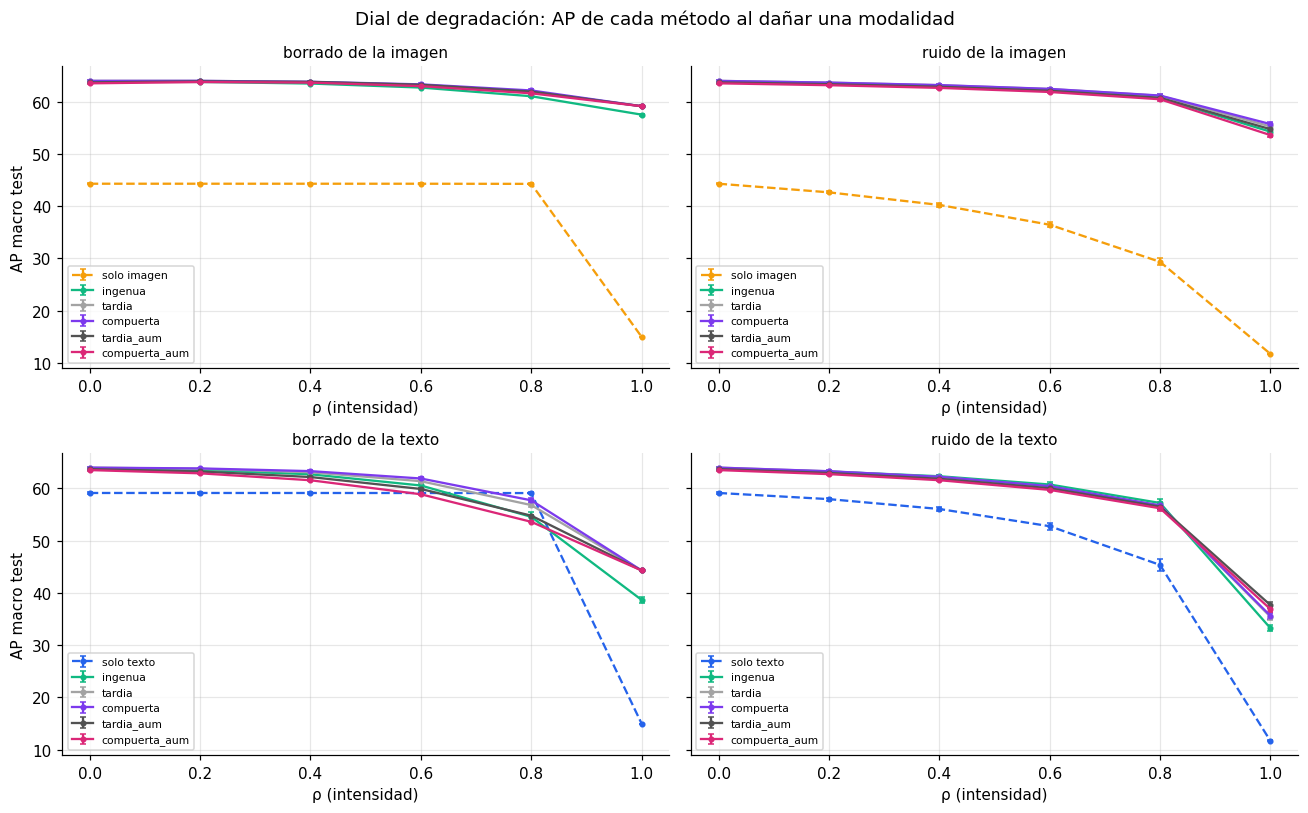

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharey=True)
for i, m in enumerate(MODS.values()):
    for j, tipo in enumerate(TIPOS):
        ax = axes[i, j]
        d = dial[(dial.modalidad == m) & (dial.tipo == tipo)]
        for met in [m] + METODOS:
            g = d[d.metodo == met].groupby('rho')['ap_macro']
            ax.errorbar(g.mean().index, 100 * g.mean(), yerr=100 * g.agg(lambda x: ic95(x)[1]), fmt='o-', ms=3,
                        capsize=2, color=COL[met], ls='--' if met == m else '-', label=f'solo {met}' if met == m else met)
        ax.set_title(f'{tipo} de la {m}', fontsize=10)
        ax.set_xlabel('ρ (intensidad)')
    axes[i, 0].set_ylabel('AP macro test')
for ax in axes.ravel():
    ax.legend(fontsize=7)
fig.suptitle('Dial de degradación: AP de cada método al dañar una modalidad')
plt.tight_layout(); plt.show()

### ¿La degradación se anuncia?

Entropía y exceso de la **rama degradada**. Las líneas horizontales son el texto en `control_tmdb` y en
`recientes_tmdb` (del C1, `exp4_sorpresa.csv`): ubican a las películas recientes en el dial.

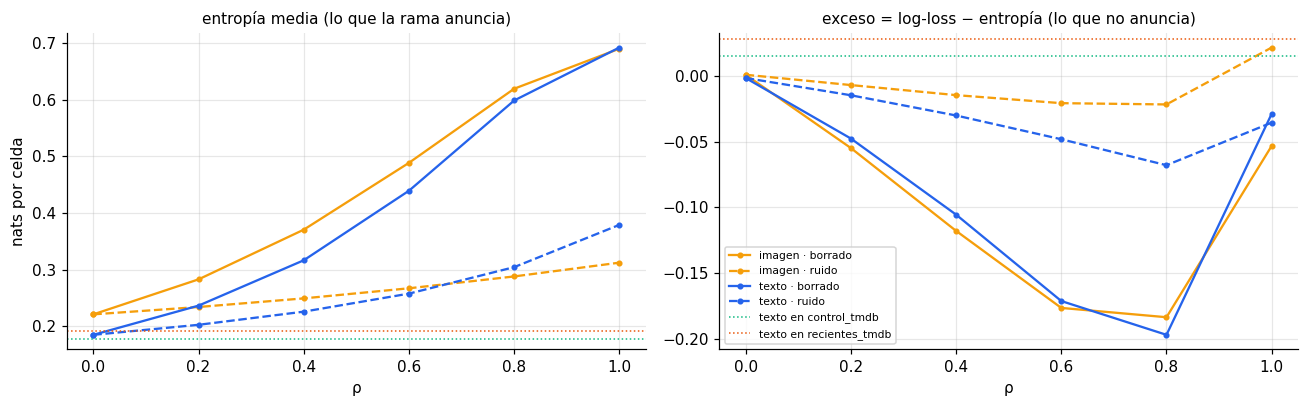

ap_macro  entropia  exceso
tipo    rho                            
borrado 0.0    0.5912    0.1852 -0.0015
        0.2    0.5912    0.2368 -0.0476
        0.4    0.5912    0.3168 -0.1056
        0.6    0.5911    0.4395 -0.1714
        0.8    0.5910    0.5988 -0.1971
        1.0    0.1498    0.6923 -0.0288
ruido   0.0    0.5912    0.1852 -0.0015
        0.2    0.5794    0.2029 -0.0147
        0.4    0.5605    0.2261 -0.0301
        0.6    0.5276    0.2579 -0.0482
        0.8    0.4535    0.3047 -0.0679
        1.0    0.1166    0.3793 -0.0355

In [7]:
sorp = pd.read_csv(f'{RES}/exp4_sorpresa.csv').set_index(['conjunto', 'modelo'])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for k, medida in enumerate(['entropia', 'exceso']):
    ax = axes[k]
    for m in MODS.values():
        for tipo, ls in zip(TIPOS, ['-', '--']):
            g = dial[(dial.modalidad == m) & (dial.tipo == tipo) & (dial.metodo == m)].groupby('rho')[medida].mean()
            ax.plot(g.index, g.values, 'o' + ls, ms=3, color=COL[m], label=f'{m} · {tipo}')
    col_sorp = {'entropia': 'entropia_media', 'exceso': 'exceso'}[medida]
    for grupo, c in [('control_tmdb', '#10b981'), ('recientes_tmdb', '#ea580c')]:
        ax.axhline(sorp.loc[(grupo, 'texto'), col_sorp], color=c, lw=1, ls=':', label=f'texto en {grupo}')
    ax.set_xlabel('ρ'); ax.set_title({'entropia': 'entropía media (lo que la rama anuncia)',
                                     'exceso': 'exceso = log-loss − entropía (lo que no anuncia)'}[medida], fontsize=10)
axes[0].set_ylabel('nats por celda'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

d = dial[(dial.metodo == 'texto') & (dial.modalidad == 'texto')].groupby(['tipo', 'rho'])[['ap_macro', 'entropia', 'exceso']].mean()
d.round(4)

### ¿La compuerta le baja el peso a la rama dañada?

Peso medio de la imagen. Al dañar el texto debería **subir**; al dañar la imagen, **bajar**.

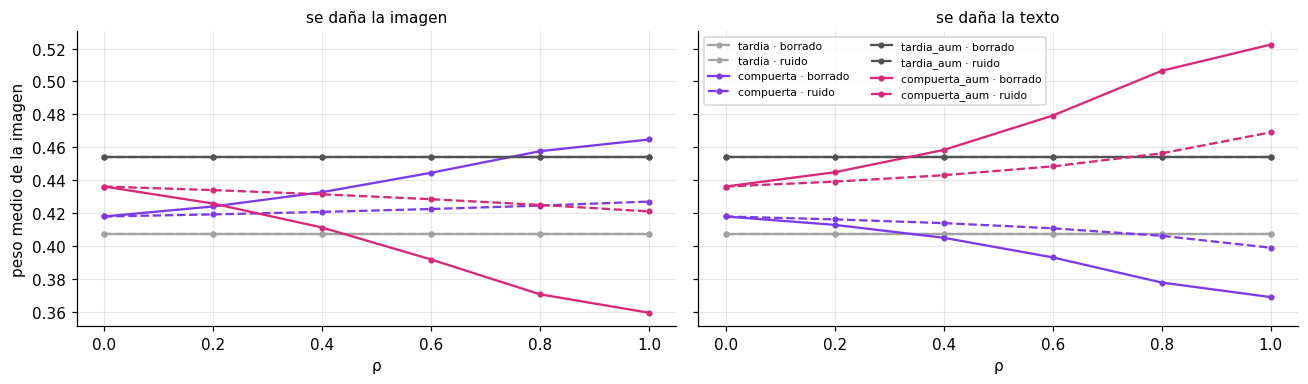

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, m in zip(axes, MODS.values()):
    for met in ['tardia', 'compuerta', 'tardia_aum', 'compuerta_aum']:
        for tipo, ls in zip(TIPOS, ['-', '--']):
            g = dial[(dial.modalidad == m) & (dial.tipo == tipo) & (dial.metodo == met)].groupby('rho')['peso_imagen'].mean()
            ax.plot(g.index, g.values, 'o' + ls, ms=3, color=COL[met], label=f'{met} · {tipo}')
    ax.set_title(f'se daña la {m}', fontsize=10); ax.set_xlabel('ρ')
axes[0].set_ylabel('peso medio de la imagen'); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

In [9]:
# Diferencias pareadas por semilla (puntos de AP)
def ap_sem(m, tipo, rho, met):
    return dial[(dial.modalidad == m) & (dial.tipo == tipo) & (dial.rho == rho) & (dial.metodo == met)].set_index('semilla')['ap_macro']

filas = []
for m in MODS.values():
    for tipo in TIPOS:
        for rho in RHOS:
            for a, b in [('compuerta_aum', 'ingenua'), ('tardia_aum', 'ingenua'), ('compuerta', 'ingenua'),
                         ('compuerta_aum', 'tardia_aum'), ('compuerta', 'tardia')]:
                med, h = ic95(100 * (ap_sem(m, tipo, rho, a) - ap_sem(m, tipo, rho, b)))
                filas.append({'modalidad': m, 'tipo': tipo, 'rho': rho, 'comparacion': f'{a} − {b}',
                              'dif_ap': med, 'ic': h, 'sin_cero': abs(med) > h})
dif_dial = pd.DataFrame(filas)
vista = dif_dial[dif_dial.rho.isin([0.0, 0.4, RHO_CRIT, 1.0])].copy()
vista['texto'] = vista.apply(lambda r: f"{r.dif_ap:+.2f} ± {r.ic:.2f}{' *' if r.sin_cero else ''}", axis=1)
print("AP, puntos (media ± IC 95% sobre semillas; * = sin el 0)")
vista.pivot_table(index=['modalidad', 'tipo', 'comparacion'], columns='rho', values='texto', aggfunc='first')

AP, puntos (media ± IC 95% sobre semillas; * = sin el 0)


rho                                                      0.0             0.4  \
modalidad tipo    comparacion                                                  
imagen    borrado compuerta − ingenua         +0.20 ± 0.15 *  +0.34 ± 0.09 *   
                  compuerta − tardia            -0.00 ± 0.01  +0.03 ± 0.02 *   
                  compuerta_aum − ingenua     -0.27 ± 0.11 *  +0.17 ± 0.10 *   
                  compuerta_aum − tardia_aum  -0.19 ± 0.03 *  -0.15 ± 0.04 *   
                  tardia_aum − ingenua          -0.08 ± 0.11  +0.32 ± 0.11 *   
          ruido   compuerta − ingenua         +0.20 ± 0.15 *  +0.24 ± 0.20 *   
                  compuerta − tardia            -0.00 ± 0.01  +0.01 ± 0.01 *   
                  compuerta_aum − ingenua     -0.27 ± 0.11 *  -0.30 ± 0.21 *   
                  compuerta_aum − tardia_aum  -0.19 ± 0.03 *  -0.22 ± 0.02 *   
                  tardia_aum − ingenua          -0.08 ± 0.11    -0.08 ± 0.21   
texto     borrado compuerta − ingenua         +0.20 ± 0.15 *  +0.60 ± 0.33 *   
                  compuerta − tardia            -0.00 ± 0.01  +0.23 ± 0.02 *   
                  compuerta_aum − ingenua     -0.27 ± 0.11 *  -1.14 ± 0.28 *   
                  compuerta_aum − tardia_aum  -0.19 ± 0.03 *  -0.61 ± 0.06 *   
                  tardia_aum − ingenua          -0.08 ± 0.11  -0.53 ± 0.26 *   
          ruido   compuerta − ingenua         +0.20 ± 0.15 *    -0.11 ± 0.46   
                  compuerta − tardia            -0.00 ± 0.01  +0.04 ± 0.01 *   
                  compuerta_aum − ingenua     -0.27 ± 0.11 *  -0.76 ± 0.40 *   
                  compuerta_aum − tardia_aum  -0.19 ± 0.03 *  -0.28 ± 0.04 *   
                  tardia_aum − ingenua          -0.08 ± 0.11  -0.48 ± 0.39 *   

rho                                                      0.8             1.0  
modalidad tipo    comparacion                                                 
imagen    borrado compuerta − ingenua         +1.11 ± 0.13 *  +1.61 ± 0.12 *  
                  compuerta − tardia          +0.23 ± 0.03 *    -0.00 ± 0.00  
                  compuerta_aum − ingenua     +0.56 ± 0.15 *  +1.61 ± 0.12 *  
                  compuerta_aum − tardia_aum  -0.33 ± 0.03 *    +0.00 ± 0.00  
                  tardia_aum − ingenua        +0.89 ± 0.14 *  +1.61 ± 0.12 *  
          ruido   compuerta − ingenua         +0.47 ± 0.35 *  +1.46 ± 0.52 *  
                  compuerta − tardia          +0.04 ± 0.01 *  +0.46 ± 0.04 *  
                  compuerta_aum − ingenua       -0.25 ± 0.37  -0.65 ± 0.51 *  
                  compuerta_aum − tardia_aum  -0.27 ± 0.01 *  -1.14 ± 0.08 *  
                  tardia_aum − ingenua          +0.03 ± 0.37  +0.48 ± 0.44 *  
texto     borrado compuerta − ingenua         +3.16 ± 1.21 *  +5.63 ± 0.52 *  
                  compuerta − tardia          +0.91 ± 0.11 *    +0.00 ± 0.00  
                  compuerta_aum − ingenua     -0.95 ± 0.93 *  +5.63 ± 0.52 *  
                  compuerta_aum − tardia_aum  -1.18 ± 0.04 *    -0.00 ± 0.00  
                  tardia_aum − ingenua          +0.23 ± 0.94  +5.63 ± 0.52 *  
          ruido   compuerta − ingenua           -0.47 ± 1.12  +2.36 ± 0.78 *  
                  compuerta − tardia            +0.02 ± 0.03  +0.18 ± 0.01 *  
                  compuerta_aum − ingenua     -1.01 ± 0.96 *  +3.65 ± 0.73 *  
                  compuerta_aum − tardia_aum  -0.31 ± 0.04 *  -0.77 ± 0.03 *  
                  tardia_aum − ingenua          -0.71 ± 0.98  +4.41 ± 0.72 *

## 4. Pocos datos de entrenamiento

Se reentrenan imagen, texto y fusión ingenua con una fracción del train (mismo protocolo y configuración del 06,
early stopping en dev completo). Con el 100% se reutilizan los modelos del 06. Para cada corrida:

- AP de cada rama y de la fusión; **ganancia** de la fusión sobre la mejor rama.
- **Índice de dependencia de la imagen** como en el 06: caída del AP de la fusión al apagar la imagen, dividida
  por la suma de las caídas al apagar cada modalidad. 0.5 = equilibrio; cerca de 0 = depende del texto.
- `tardia` y `compuerta` ajustadas en dev sobre las ramas de esa fracción (logits calibrados con su temperatura).

Son 45 entrenamientos: unos 5 minutos en CPU y menos con GPU.

In [10]:
CFG = {k: CONFIG[k] for k in ['dim_proy', 'dropout', 'lr', 'weight_decay', 'batch', 'max_epocas', 'paciencia']}
SEM_PD = SEMILLAS[:N_SEM_PD]
tr = idx_mm['train']
Ytr_all, Ydev_all = Y_mm[tr], Y_mm[idx_mm['dev']]
tens = lambda X, mods, apagar=None: [torch.zeros(len(X[m]), X[m].shape[1], device=device) if m == apagar
                                     else torch.from_numpy(X[m]).to(device) for m in mods]

t0 = time.time()
filas = []
for f in FRACCIONES:
    for s in SEM_PD:
        sub = np.sort(np.random.default_rng((SEED, s)).choice(len(tr), max(int(f * len(tr)), 64), replace=False))
        Xtr = {m: Xz_mm[m][tr[sub]] for m in MODS}
        lg = {}
        for n, mods in art['modalidades'].items():
            if f == 1.0 and (n, s) in MODELOS:
                modelo = MODELOS[(n, s)]
            else:
                modelo, _ = entrenar(tens(Xtr, mods), torch.from_numpy(Ytr_all[sub]).to(device),
                                     tens(XS['dev'], mods), Ydev_all, CFG, s)
            dev_raw = predecir_logits(modelo, tens(XS['dev'], mods))[:, COLS]
            T = ajustar_temperatura(YS['dev'], dev_raw)
            lg[n] = {'dev': dev_raw / T, 'test': predecir_logits(modelo, tens(XS['test'], mods))[:, COLS] / T}
            if n == 'fusion_ingenua':
                lg['sin_imagen'] = predecir_logits(modelo, tens(XS['test'], mods, 'img'))[:, COLS]
                lg['sin_texto'] = predecir_logits(modelo, tens(XS['test'], mods, 'txt'))[:, COLS]
        ap = {n: ap_macro(YS['test'], lg[n]['test']) for n in art['modalidades']}
        caida_img = ap['fusion_ingenua'] - ap_macro(YS['test'], lg['sin_imagen'])
        caida_txt = ap['fusion_ingenua'] - ap_macro(YS['test'], lg['sin_texto'])
        fila = {'fraccion': f, 'n_train': len(sub), 'semilla': s, 'ap_imagen': ap['imagen'], 'ap_texto': ap['texto'],
                'ap_ingenua': ap['fusion_ingenua'], 'ganancia_fusion': ap['fusion_ingenua'] - max(ap['imagen'], ap['texto']),
                'caida_sin_imagen': caida_img, 'caida_sin_texto': caida_txt,
                'indice_dependencia_imagen': caida_img / (caida_img + caida_txt)}
        Zd = np.stack([lg[n]['dev'] for n in ENTRADAS], -1)
        Zt = np.stack([lg[n]['test'] for n in ENTRADAS], -1)
        for met in ['tardia', 'compuerta']:
            fila[f'ap_{met}'] = ap_macro(YS['test'], combinar(ajustar_compuerta(Zd, YS['dev'], met == 'compuerta'), Zt)[0])
        filas.append(fila)
    print(f"  fracción {f:4.2f} lista | {time.time() - t0:.0f} s")
pocos = pd.DataFrame(filas)
pocos.groupby('fraccion').mean(numeric_only=True).drop(columns='semilla').round(4)

  fracción 0.02 lista | 16 s
  fracción 0.05 lista | 31 s
  fracción 0.10 lista | 43 s
  fracción 0.25 lista | 55 s
  fracción 0.50 lista | 70 s
  fracción 1.00 lista | 74 s


,n_train,ap_imagen,ap_texto,ap_ingenua,ganancia_fusion,caida_sin_imagen,caida_sin_texto,indice_dependencia_imagen,ap_tardia,ap_compuerta
fraccion,,,,,,,,,,
0.02,310.0,0.2953,0.4326,0.4683,0.0357,0.0362,0.2055,0.1498,0.4806,0.4810
0.05,776.0,0.3397,0.4756,0.5237,0.0480,0.0518,0.2236,0.1880,0.5295,0.5297
0.10,1553.0,0.3722,0.5172,0.5619,0.0447,0.0506,0.2434,0.1720,0.5714,0.5717
0.25,3882.0,0.4075,0.5558,0.6018,0.0460,0.0558,0.2515,0.1816,0.6071,0.6074
0.50,7765.0,0.4296,0.5755,0.6230,0.0475,0.0607,0.2521,0.1940,0.6256,0.6258
1.00,15531.0,0.4432,0.5904,0.6374,0.0470,0.0634,0.2479,0.2037,0.6388,0.6389


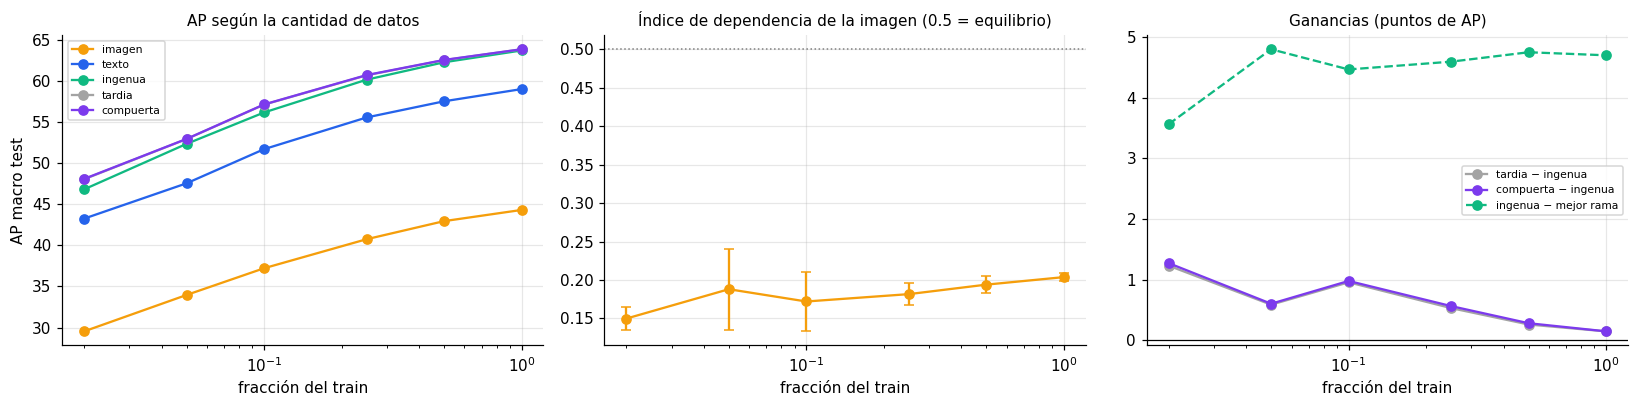

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
g = pocos.groupby('fraccion')
x = g.size().index
for n, c in [('imagen', 'imagen'), ('texto', 'texto'), ('ingenua', 'ingenua'), ('tardia', 'tardia'), ('compuerta', 'compuerta')]:
    axes[0].plot(x, 100 * g[f'ap_{n}'].mean(), 'o-', color=COL[c], label=n)
axes[0].set_ylabel('AP macro test'); axes[0].set_title('AP según la cantidad de datos', fontsize=10)
axes[1].errorbar(x, g['indice_dependencia_imagen'].mean(), yerr=g['indice_dependencia_imagen'].agg(lambda v: ic95(v)[1]),
                 fmt='o-', capsize=3, color=COL['imagen'])
axes[1].axhline(0.5, color='gray', ls=':', lw=1)
axes[1].set_title('Índice de dependencia de la imagen (0.5 = equilibrio)', fontsize=10)
for n, c in [('tardia', 'tardia'), ('compuerta', 'compuerta')]:
    axes[2].plot(x, 100 * (g[f'ap_{n}'].mean() - g['ap_ingenua'].mean()), 'o-', color=COL[c], label=f'{n} − ingenua')
axes[2].plot(x, 100 * g['ganancia_fusion'].mean(), 'o--', color=COL['ingenua'], label='ingenua − mejor rama')
axes[2].axhline(0, color='black', lw=0.8); axes[2].set_title('Ganancias (puntos de AP)', fontsize=10)
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('fracción del train'); ax.legend(fontsize=7) if ax.get_legend_handles_labels()[0] else None
plt.tight_layout(); plt.show()

## 5. ¿Y en las películas reales? Los cuatro grupos del 08

Se aplican las compuertas `_aum` a los mismos grupos del C1, sin cambiar nada. Si la degradación de las
recientes fuera del tipo *anunciado*, `compuerta_aum` debería ayudar ahí.

In [12]:
tm = pd.read_parquet(f'{DATA}/tmdb_meta.parquet')
X_tm = aplicar_estandarizacion({'img': np.load(f'{EMB}/tmdb_clip_img.npy'), 'txt': np.load(f'{EMB}/tmdb_distilbert_txt.npy')},
                               art['stats_estandarizacion'])
Y_tm = tm[[f'hoy_{g}' for g in G_ENT]].values.astype(np.float32)
i_ctrl, i_rec = np.where(tm['grupo'] == 'control')[0], np.where(tm['grupo'] == 'reciente')[0]
filas_ctrl = tm['fila_hdf5'].values[i_ctrl]
GRUPOS = {'test_mmimdb': (XS['test'], Y_mm[idx_mm['test']]),
          'control_mmimdb': ({m: Xz_mm[m][filas_ctrl] for m in MODS}, Y_mm[filas_ctrl]),
          'control_tmdb': ({m: X_tm[m][i_ctrl] for m in MODS}, Y_tm[i_ctrl]),
          'recientes_tmdb': ({m: X_tm[m][i_rec] for m in MODS}, Y_tm[i_rec])}

filas = []
for gname, (X, Y) in GRUPOS.items():
    Y = Y[:, COLS]
    for s in SEMILLAS:
        Z = {n: logits_cal(n, s, 'test', None, X) for n in ENTRADAS + ['fusion_ingenua']}
        Zst = np.stack([Z[n] for n in ENTRADAS], -1)
        filas.append({'grupo': gname, 'semilla': s, 'metodo': 'ingenua', 'ap_macro': ap_macro(Y, Z['fusion_ingenua'])})
        for met in METODOS[1:]:
            z, w = combinar(COMPUERTAS[(met, s)], Zst)
            filas.append({'grupo': gname, 'semilla': s, 'metodo': met, 'ap_macro': ap_macro(Y, z),
                          'peso_imagen': float(w[..., 0].mean())})
grupos = pd.DataFrame(filas)
base = grupos[grupos.metodo == 'ingenua'].set_index(['grupo', 'semilla'])['ap_macro']
grupos = grupos.merge(base.rename('ap_ingenua').reset_index(), on=['grupo', 'semilla'])
grupos['dif_vs_ingenua'] = 100 * (grupos['ap_macro'] - grupos['ap_ingenua'])
fmt = lambda x: '{:+.2f} ± {:.2f}'.format(*ic95(x))
print("AP − ingenua (puntos, media ± IC 95% sobre semillas)")
print(grupos[grupos.metodo != 'ingenua'].pivot_table(index='metodo', columns='grupo', values='dif_vs_ingenua', aggfunc=fmt)
      .loc[METODOS[1:], list(GRUPOS)].to_string())
print("\nPeso medio de la imagen")
grupos[grupos.metodo != 'ingenua'].pivot_table(index='metodo', columns='grupo', values='peso_imagen').loc[METODOS[1:], list(GRUPOS)].round(3)

AP − ingenua (puntos, media ± IC 95% sobre semillas)
grupo           test_mmimdb control_mmimdb  control_tmdb recientes_tmdb
metodo                                                                 
tardia         +0.21 ± 0.16   +0.02 ± 0.40  +0.14 ± 0.36   -0.04 ± 0.15
compuerta      +0.20 ± 0.15   -0.07 ± 0.40  +0.11 ± 0.36   -0.05 ± 0.14
tardia_aum     -0.08 ± 0.11   -0.33 ± 0.37  -0.10 ± 0.38   -0.31 ± 0.19
compuerta_aum  -0.27 ± 0.11   -0.48 ± 0.42  -0.33 ± 0.40   -0.42 ± 0.17

Peso medio de la imagen


grupo,test_mmimdb,control_mmimdb,control_tmdb,recientes_tmdb
metodo,,,,
tardia,0.407,0.407,0.407,0.407
compuerta,0.418,0.418,0.419,0.417
tardia_aum,0.454,0.454,0.454,0.454
compuerta_aum,0.436,0.437,0.434,0.437


## 6. Predicciones

In [13]:
def dial_sem(m, tipo, rho, met, medida):
    return dial[(dial.modalidad == m) & (dial.tipo == tipo) & (dial.rho == rho) & (dial.metodo == met)].set_index('semilla')[medida]

def fmt_ic(v, k=1, u=''):
    m, h = ic95(k * np.asarray(v))
    return m, h, f'{m:+.3f} ± {h:.3f}{u}' if k == 1 else f'{m:+.2f} ± {h:.2f}{u}'

R = RHO_CRIT
crit = []
d1 = dial_sem('texto', 'borrado', R, 'texto', 'entropia') - dial_sem('texto', 'borrado', 0.0, 'texto', 'entropia')
m, h, t = fmt_ic(d1, u=' nats')
crit.append({'prediccion': f'P1. borrar el texto (ρ={R}) sube su entropía', 'valor': t, 'cumple': m - h > 0})

ex = lambda tipo: dial_sem('texto', tipo, R, 'texto', 'exceso') - dial_sem('texto', tipo, 0.0, 'texto', 'exceso')
m, h, t = fmt_ic(ex('ruido') - ex('borrado'), u=' nats')
crit.append({'prediccion': f'P2. el exceso del texto sube más con ruido que con borrado (ρ={R})', 'valor': t, 'cumple': m - h > 0})

gan = lambda tipo: dial_sem('texto', tipo, R, 'compuerta_aum', 'ap_macro') - dial_sem('texto', tipo, R, 'tardia_aum', 'ap_macro')
m, h, t = fmt_ic(gan('borrado'), 100, ' pts')
crit.append({'prediccion': f'P3. borrado del texto (ρ={R}): compuerta_aum > tardia_aum', 'valor': t, 'cumple': m - h > 0})
m, h, t = fmt_ic(gan('borrado') - gan('ruido'), 100, ' pts')
crit.append({'prediccion': 'P4. esa ganancia es mayor con borrado que con ruido', 'valor': t, 'cumple': m - h > 0})

m, h, t = fmt_ic(dial_sem('texto', 'borrado', 0.0, 'compuerta_aum', 'ap_macro') - dial_sem('texto', 'borrado', 0.0, 'ingenua', 'ap_macro'), 100, ' pts')
crit.append({'prediccion': 'P5. en test limpio, compuerta_aum no pierde más de 0.5 pts contra la ingenua',
             'valor': t, 'cumple': m - h > -100 * MARGEN_NO_INFERIORIDAD})

pd_sem = lambda f, col: pocos[pocos.fraccion == f].set_index('semilla')[col]
m, h, t = fmt_ic(pd_sem(FRAC_CRIT, 'indice_dependencia_imagen') - pd_sem(1.0, 'indice_dependencia_imagen'))
crit.append({'prediccion': f'P6. índice de dependencia de la imagen menor con {FRAC_CRIT:.0%} que con 100%', 'valor': t, 'cumple': m + h < 0})
v = lambda f: pd_sem(f, 'ap_tardia') - pd_sem(f, 'ap_ingenua')
m, h, t = fmt_ic(v(FRAC_CRIT) - v(1.0), 100, ' pts')
crit.append({'prediccion': f'P7. ventaja de tardia sobre la ingenua mayor con {FRAC_CRIT:.0%} que con 100%', 'valor': t, 'cumple': m - h > 0})

rec = grupos[(grupos.grupo == 'recientes_tmdb') & (grupos.metodo == 'compuerta_aum')]['dif_vs_ingenua']
crit.append({'prediccion': '(sin predicción) compuerta_aum − ingenua en recientes_tmdb', 'valor': fmt_ic(rec, u=' pts')[2], 'cumple': None})
criterios = pd.DataFrame(crit)
criterios

,prediccion,valor,cumple
0,P1. borrar el texto (ρ=0.8) sube su entropía,+0.414 ± 0.001 nats,True
1,P2. el exceso del texto sube más con ruido que...,+0.129 ± 0.005 nats,True
2,P3. borrado del texto (ρ=0.8): compuerta_aum >...,-1.18 ± 0.04 pts,False
3,P4. esa ganancia es mayor con borrado que con ...,-0.87 ± 0.00 pts,False
4,"P5. en test limpio, compuerta_aum no pierde má...",-0.27 ± 0.11 pts,True
5,P6. índice de dependencia de la imagen menor c...,-0.016 ± 0.050,False
6,P7. ventaja de tardia sobre la ingenua mayor c...,+0.44 ± 1.14 pts,False
7,(sin predicción) compuerta_aum − ingenua en re...,-0.420 ± 0.174 pts,None


**Cómo leer en conjunto:**
- Si P1 y P3 se cumplen y P4 también, la compuerta funciona **cuando la rama dañada anuncia su incertidumbre**,
  y el fracaso del C1 en las recientes se explica porque ahí el texto falla como en el *ruido*, no como en el
  *borrado* (comparar con dónde caen las líneas de las recientes en la figura de entropía y exceso).
- Si P6 y P7 se cumplen, el desbalance clásico (depender solo del texto) **sí aparece**, pero solo con pocos datos:
  con todo MM-IMDB los encoders congelados ya dan ramas lo bastante buenas para que la concatenación funcione.

## Guardado

- `exp5_dial.csv`: AP, peso de la imagen, entropía y exceso por modalidad, tipo, ρ, método y semilla.
- `exp5_dial_diferencias.csv`: diferencias pareadas entre métodos a lo largo del dial.
- `exp5_pocos_datos.csv`: AP, ganancia e índice de dependencia por fracción y semilla.
- `exp5_grupos.csv`: los métodos `_aum` en los cuatro grupos del 08.
- `exp5_parametros.csv`, `exp5_criterios.csv`, `exp5_config.json`.
- `exp5_compuertas_aum.pt`: compuertas `_aum` (mismo formato que `exp4_compuertas.pt`, se leen con
  `src.fusion.cargar_compuertas`).

In [14]:
dial.to_csv(f'{RES}/exp5_dial.csv', index=False)
dif_dial.to_csv(f'{RES}/exp5_dial_diferencias.csv', index=False)
pocos.to_csv(f'{RES}/exp5_pocos_datos.csv', index=False)
grupos.to_csv(f'{RES}/exp5_grupos.csv', index=False)
param.to_csv(f'{RES}/exp5_parametros.csv', index=False)
criterios.to_csv(f'{RES}/exp5_criterios.csv', index=False)
torch.save({'entradas': {m: ENTRADAS for m in ['tardia_aum', 'compuerta_aum']},
            'incertidumbre': {'tardia_aum': False, 'compuerta_aum': True}, 'generos': GENEROS,
            'compuertas': {f'{met}_s{s}': m.state_dict() for (met, s), m in COMP_AUM.items()}},
           f'{RES}/exp5_compuertas_aum.pt')
with open(f'{RES}/exp5_config.json', 'w') as fh:
    json.dump({'generos': GENEROS, 'semillas': SEMILLAS, 'semillas_pocos_datos': SEM_PD, 'rhos': RHOS,
               'rhos_aumento': RHOS_AUM, 'rho_criterios': RHO_CRIT, 'fracciones': FRACCIONES,
               'fraccion_criterios': FRAC_CRIT, 'margen_no_inferioridad': MARGEN_NO_INFERIORIDAD,
               'metodos': METODOS}, fh, indent=2)
print(sorted(f for f in os.listdir(RES) if f.startswith('exp5')))

['exp5_compuertas_aum.pt', 'exp5_config.json', 'exp5_criterios.csv', 'exp5_dial.csv', 'exp5_dial_diferencias.csv', 'exp5_grupos.csv', 'exp5_parametros.csv', 'exp5_pocos_datos.csv']
